# Qiskit Fall Fest 2026 — Challenge 4: Quantum Correlation Switch
**IBM Quantum · Vishnu Institute of Technology, Bhimavaram**

**Goal:** Build a two-qubit circuit that can be *switched* between two behaviours:
- **Part A:** correlated outcomes (`00` and `11`)
- **Part B:** opposite outcomes (`01` and `10`)

**Constraints followed:** exactly 2 qubits, both measured, at most 4 gates before measurement, only workshop gates (H, CNOT, X), 100 shots per experiment.

## 1. Setup

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

SHOTS = 100
sim = AerSimulator()

def run(qc, shots=SHOTS):
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

## 2. The design: a one-gate "switch"

Both parts share the same core, the Bell-state circuit:
1. **H** on qubit 0 creates a superposition.
2. **CNOT** (control = qubit 0, target = qubit 1) entangles the qubits, giving (|00⟩ + |11⟩)/√2.

The **switch** is an optional **X gate on qubit 1** placed after the CNOT:
- **Switch OFF** (no X) → correlated outcomes.
- **Switch ON** (X on qubit 1) → opposite outcomes.

The function below builds either version:

In [2]:
def correlation_switch(opposite: bool) -> QuantumCircuit:
    qc = QuantumCircuit(2, 2, name="Part B" if opposite else "Part A")
    qc.h(0)
    qc.cx(0, 1)
    if opposite:
        qc.x(1)          # the switch
    qc.measure([0, 1], [0, 1])
    return qc

## 3. Predictions (before running)

- **Part A (H, CNOT):** the state is (|00⟩ + |11⟩)/√2, so `00` and `11` should dominate at about 50 % each.
- **Part B (H, CNOT, X):** the state is (|01⟩ + |10⟩)/√2, so `01` and `10` should dominate at about 50 % each.
- **Will all four outcomes appear?** No. In each circuit only two of the four outcomes are possible. The other two have probability 0 in an ideal simulator (a real device would show a few of them due to noise).
- **Why are some outcomes much more frequent?** The qubits are entangled. Qubit 1 is not independent of qubit 0, so only the outcome pairs allowed by the entangled state can occur.

## 4. Part A: correlated outcomes (2 gates: H, CNOT)

In [3]:
qc_a = correlation_switch(opposite=False)
print(qc_a.draw("text"))

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


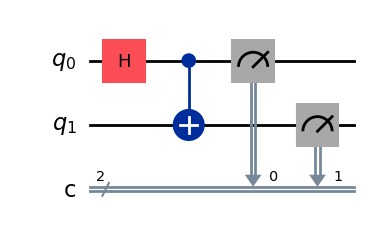

In [4]:
qc_a.draw("mpl")

## 5. Part B: opposite outcomes (3 gates: H, CNOT, X)

In [5]:
qc_b = correlation_switch(opposite=True)
print(qc_b.draw("text"))

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


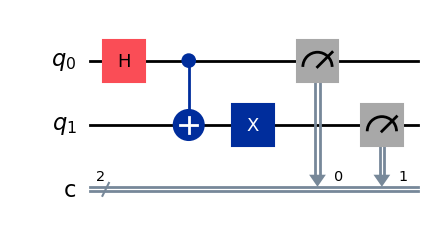

In [6]:
qc_b.draw("mpl")

## 6. Run both circuits for 100 shots

In [7]:
counts_a = run(qc_a)
counts_b = run(qc_b)

print("Part A (correlated) :", dict(sorted(counts_a.items())))
print("Part B (opposite)   :", dict(sorted(counts_b.items())))

Part A (correlated) : {'00': 53, '11': 47}
Part B (opposite)   : {'01': 49, '10': 51}


## 7. Part C: Histogram comparison

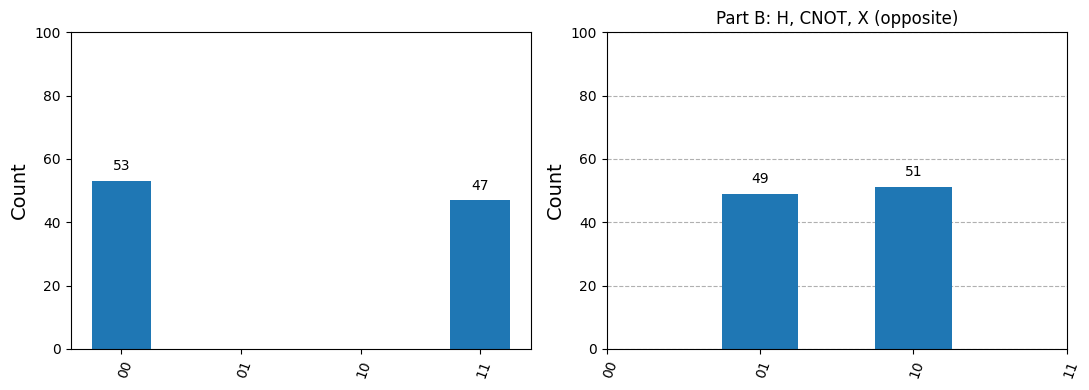

In [8]:
all_states = ['00', '01', '10', '11']
full_a = {s: counts_a.get(s, 0) for s in all_states}
full_b = {s: counts_b.get(s, 0) for s in all_states}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_histogram(full_a, ax=axes[0], title="Part A: H, CNOT (correlated)")
plot_histogram(full_b, ax=axes[1], title="Part B: H, CNOT, X (opposite)")
for ax in axes:
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

In [9]:
def summarize(name, c):
    same = c.get('00', 0) + c.get('11', 0)
    diff = c.get('01', 0) + c.get('10', 0)
    print(f"{name:<22} same (00+11): {same:>3}   opposite (01+10): {diff:>3}")

summarize("Part A (correlated)", counts_a)
summarize("Part B (opposite)", counts_b)

Part A (correlated)    same (00+11): 100   opposite (01+10):   0
Part B (opposite)      same (00+11):   0   opposite (01+10): 100


## 8. Comparison and explanation

**Which outcomes are dominant in Part A?** `00` and `11`, each roughly half of the 100 shots. `01` and `10` did not appear.

**Which outcomes are dominant in Part B?** `01` and `10`, each roughly half of the shots. `00` and `11` did not appear.

**What changed between the two circuits?** Only one gate: an **X gate on qubit 1**, added after the CNOT in Part B.

**Why did the measurement relationship change?** The H + CNOT part entangles the qubits into (|00⟩ + |11⟩)/√2, so they always match. The X gate flips qubit 1 in *every* term of the superposition: |00⟩ → |01⟩ and |11⟩ → |10⟩, giving (|01⟩ + |10⟩)/√2. So the qubits still have a perfect relationship, but it flips from "equal" to "opposite".

**How the circuit produces the different correlations:** the individual result of each qubit is random (about 50/50), but the *relationship* between the two is fixed by the entanglement from H + CNOT. The optional X gate acts as a switch that chooses which relationship we see. Predictions matched the results: only two of four outcomes appear in each experiment, and the small imbalance between the two outcomes (for example 52 vs 48) is just random shot noise from using 100 shots.